In [2]:
# Install latest Qiskit nightly packages and dependencies
!pip install -U qiskit qiskit-aer qiskit-algorithms matplotlib pylatexenc

In [3]:
import random
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit_aer import Aer

# Set random seed
SEED = 42
random.seed(SEED)
sim = Aer.get_backend('aer_simulator')


In [12]:
# state preparation
def prepare_state(qc, q, bit, basis):

    if bit == 0:
      if basis == 'X':
        qc.h(q)  # |+> state
    if bit == 1:
      if basis == 'Z':
        qc.x(q) # |1> state
      if basis == 'X':
        qc.x(q)
        qc.h(q)  # |-> state


# Bob or Eve measures qubit q in the given basis
def measure(qc, q, basis):
    if basis == 'X':
        qc.h(q)        # rotate X basis into Z basis before measuring
    qc.measure(q, q)

# run a circuit and return the measured bits in the right order

def run_circuit(qc, seed):

    #compiled = transpile(qc, sim)
    result = sim.run(qc, shots=1, seed_simulator=seed).result()
    counts = result.get_counts()

    keys = counts.keys()
    key = list(keys)[0]
    meas = list(key)
    meas_ints = []
    # bits = []
    for n in range(len(meas)):
      meas_ints.append(int(meas[n]))

    # reverse the order to match our input
    bits = meas_ints[::-1]
    return bits


In [83]:
def bb84_with_eve(n_qubits, f, k, seed, threshold=0.11):

  random.seed(seed)

  # Alice chooses randomly her bases and bits, Bob chooses randomly his bases

  alice_bits  = [random.randint(0, 1) for _ in range(n_qubits)]
  alice_bases = [random.choice(['Z', 'X']) for _ in range(n_qubits)]
  bob_bases   = [random.choice(['Z', 'X']) for _ in range(n_qubits)]


  # Eve decides which qubits to attack (with probability f) and chooses a random basis for each qubit
  eve_attacks = [random.random() < f for _ in range(n_qubits)]
  eve_bases   = [random.choice(['Z', 'X']) for _ in range(n_qubits)]


  if sum(eve_attacks) > 0:

    # first circuit - Alice prepares her states and Eve measures the attacked qubits
    qc1 = QuantumCircuit(n_qubits, n_qubits)

    for n in range(n_qubits):
      prepare_state(qc1, n, alice_bits[n], alice_bases[n])

    qc1.barrier()

    for n in range(n_qubits):
      if eve_attacks[n]:
        measure(qc1, n, eve_bases[n])

    # run the first circuit to get Eve's results
    eve_bits = run_circuit(qc1, seed)

  else:
    eve_bits = []

  # second circuit - what Bob receives, then Bob measures
  qc2 = QuantumCircuit(n_qubits, n_qubits)

  for n in range(n_qubits):
    if eve_attacks[n]:
      prepare_state(qc2, n, eve_bits[n], eve_bases[n])       # Eve resends her result
    else:
      prepare_state(qc2, n, alice_bits[n], alice_bases[n])   # original state is passed

  qc2.barrier()

  for n in range(n_qubits):
    measure(qc2, n, bob_bases[n])

  # run second circuit to get Bob's results
  bob_bits = run_circuit(qc2, seed - 1)


  # key sifting - keep positions where Alice and Bob used the same basis
  alice_sifted = []
  bob_sifted = []

  for n in range(n_qubits):
    if alice_bases[n] == bob_bases[n]:
      alice_sifted.append(alice_bits[n])
      bob_sifted.append(bob_bits[n])


  # choose k random sifted positions, count the errors, calculate QBER

  if len(alice_sifted) == 0:
    return {"sifted_len": 0, "sifted_key": [], "n_attacked": sum(eve_attacks), "qber": 0.0, "decision": "accept"}

  k_used = min(k, len(alice_sifted))
  sample = random.sample(range(len(alice_sifted)), k_used)

  errors = 0
  for i in sample:
    if alice_sifted[i] != bob_sifted[i]:
      errors += 1

  qber = errors / k_used

  # decide whether to keep or abort the sifted key

  if qber > threshold:
    decision = "abort"
    final_key = []
  else:
    decision = "accept"
    final_key = alice_sifted

  return {"sifted_len": len(alice_sifted), "sifted_key": final_key,"n_attacked": sum(eve_attacks), "qber": qber, "decision": decision}



In [84]:
# fixed parameters
n_qubits = 24       # keep <= 25 for fast multi-qubit circuit simulation
k = 10              # number of sampled sifted bits per run
i_runs = 100        # number of repetitions (i) for each value of f

In [85]:
def run_experiment(i_runs, k, n_qubits, f, base_seed=SEED, threshold=0.11):
    qber_list = []

    for run in range(i_runs):
        # give each repetition a unique and reproducible seed
        run_seed = base_seed + run
        output = bb84_with_eve(n_qubits=n_qubits, f=f, k=k, seed=run_seed, threshold=threshold)

        qber_list.append(output["qber"])

    mean_qber = np.mean(qber_list) # mean
    std_qber = np.std(qber_list) # standard deriviation
    overall_decision = "abort" if mean_qber > threshold else "accept"

    print(f"f = {f:.2f} | expected QBER = {f/4:.3f} | mean QBER = {mean_qber:.3f} (+/- {std_qber:.3f} | mean decision: {overall_decision})")

    return {
        "f": f,
        "mean_qber": mean_qber,
        "std_qber": std_qber,
        "qber_list": qber_list
    }

# Experiment 1 - no Eve (f = 0), expected QBER = 0

In [86]:
print("=== Experiment 1: No Eve (f = 0) ===")
exp1 = run_experiment(i_runs=i_runs, k=k, n_qubits=n_qubits, f=0.0, threshold=0.11)

=== Experiment 1: No Eve (f = 0) ===
f = 0.00 | expected QBER = 0.000 | mean QBER = 0.000 (+/- 0.000 | mean decision: accept)


# Experiment 2 - full intercept-resend attack (f = 1), expected QBER = 0.25

In [87]:
print("=== Experiment 2: full intercept-resend attack (f = 1) ===")
exp2 = run_experiment(i_runs=i_runs, k=k, n_qubits=n_qubits, f=1.0, threshold=0.11)

=== Experiment 2: full intercept-resend attack (f = 1) ===
f = 1.00 | expected QBER = 0.250 | mean QBER = 0.235 (+/- 0.148 | mean decision: abort)


# Experiment 3 - partial intercept-resend attack ( 0 < f < 1), expected QBER = f/4

In [88]:
print("=== Experiment 3: partial intercept-resend Attack (0 < f < 1) ===")
f_values = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

for j in f_values:
    result = run_experiment(i_runs=i_runs, k=k, n_qubits=n_qubits, f=j, threshold=0.11)

=== Experiment 3: partial intercept-resend Attack (0 < f < 1) ===
f = 0.10 | expected QBER = 0.025 | mean QBER = 0.029 (+/- 0.053 | mean decision: accept)
f = 0.20 | expected QBER = 0.050 | mean QBER = 0.052 (+/- 0.067 | mean decision: accept)
f = 0.30 | expected QBER = 0.075 | mean QBER = 0.077 (+/- 0.076 | mean decision: accept)
f = 0.40 | expected QBER = 0.100 | mean QBER = 0.096 (+/- 0.089 | mean decision: accept)
f = 0.50 | expected QBER = 0.125 | mean QBER = 0.123 (+/- 0.112 | mean decision: abort)
f = 0.60 | expected QBER = 0.150 | mean QBER = 0.148 (+/- 0.119 | mean decision: abort)
f = 0.70 | expected QBER = 0.175 | mean QBER = 0.171 (+/- 0.127 | mean decision: abort)
f = 0.80 | expected QBER = 0.200 | mean QBER = 0.197 (+/- 0.142 | mean decision: abort)
f = 0.90 | expected QBER = 0.225 | mean QBER = 0.219 (+/- 0.145 | mean decision: abort)


# Experiment 4 - partial intercept-resend attack with threshold (f = 0.44), expected QBER = 0.11

In [89]:
print("=== Experiment 4 - partial intercept-resend attack with threshold  (f = 0.44) ===")
exp4 = run_experiment(i_runs=1000, k=k, n_qubits=n_qubits, f=0.44, threshold=0.11)

=== Experiment 4 - partial intercept-resend attack with threshold  (f = 0.44) ===
f = 0.44 | expected QBER = 0.110 | mean QBER = 0.115 (+/- 0.101 | mean decision: abort)


# Single test to illustrate the design

In [107]:
# Alice chooses randomly her bases and bits, Bob chooses randomly his bases
random.seed(SEED)
n_qubits = 20
f = 0.25          # probability that Eve attacks a qubit
k = 10            # number of sifted bits to compare
threshold = 0.11

alice_bits  = [random.randint(0, 1) for _ in range(n_qubits)]
alice_bases = [random.choice(['Z', 'X']) for _ in range(n_qubits)]
bob_bases   = [random.choice(['Z', 'X']) for _ in range(n_qubits)]

print("Alice bits :", alice_bits)
print("Alice bases:", alice_bases)
print("Bob bases  :", bob_bases)

Alice bits : [0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1]
Alice bases: ['Z', 'Z', 'X', 'X', 'X', 'Z', 'Z', 'X', 'Z', 'Z', 'X', 'Z', 'X', 'X', 'X', 'Z', 'X', 'Z', 'X', 'Z']
Bob bases  : ['X', 'X', 'Z', 'Z', 'Z', 'Z', 'X', 'Z', 'Z', 'Z', 'X', 'X', 'X', 'X', 'Z', 'X', 'X', 'Z', 'X', 'Z']


In [108]:
# Eve decides which qubits to attack (with probability f) and chooses a random basis for each qubit
eve_attacks = [random.random() < f for _ in range(n_qubits)]
eve_bases   = [random.choice(['Z', 'X']) for _ in range(n_qubits)]

print("Eve attacks:", eve_attacks)
print("Eve bases  :", eve_bases)

Eve attacks: [False, True, False, True, False, False, False, False, False, False, False, True, True, False, False, True, False, False, False, False]
Eve bases  : ['X', 'X', 'Z', 'X', 'Z', 'Z', 'X', 'X', 'X', 'X', 'Z', 'Z', 'X', 'Z', 'Z', 'Z', 'Z', 'Z', 'X', 'Z']


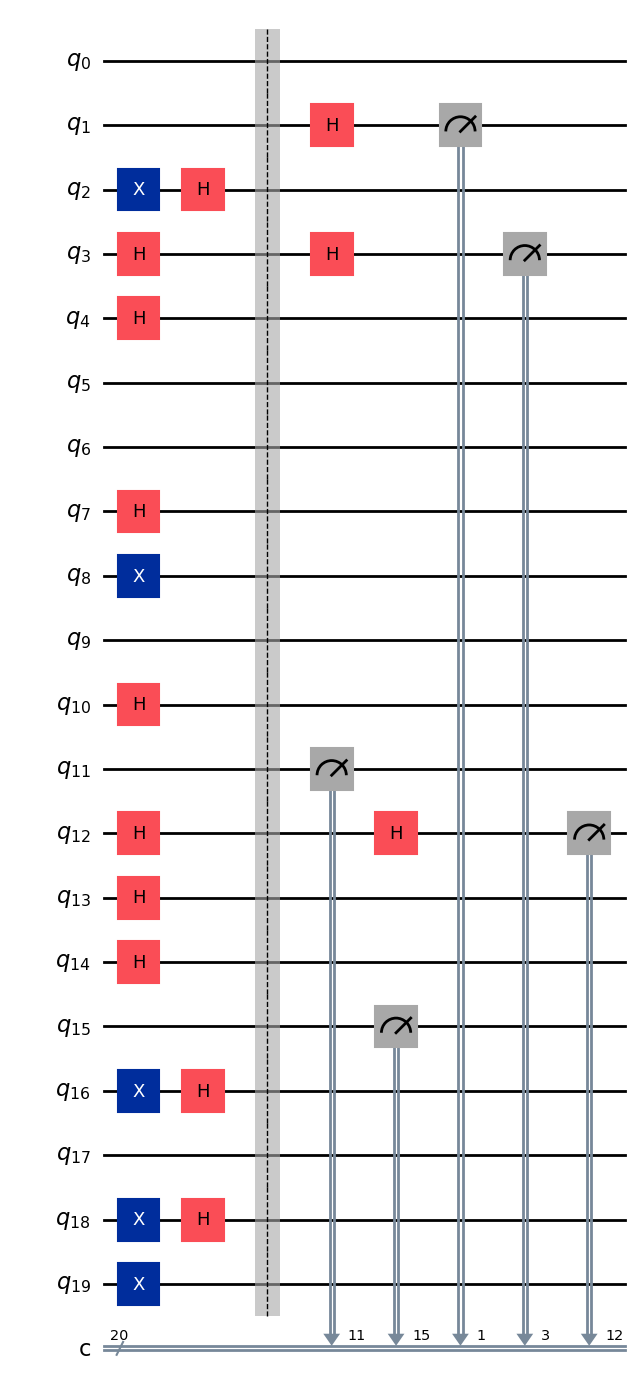

In [109]:
# first circuit - Alice prepares her states and Eve measures the attacked qubits
qc1 = QuantumCircuit(n_qubits, n_qubits)

for n in range(n_qubits):
    prepare_state(qc1, n, alice_bits[n], alice_bases[n])

qc1.barrier()

for n in range(n_qubits):
    if eve_attacks[n]:
        measure(qc1, n, eve_bases[n])

qc1.draw("mpl", style="iqp")

In [110]:
# run the first circuit to get Eve's results
eve_bits = run_circuit(qc1, SEED)
print("Eve bits:", eve_bits)

Eve bits: [0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


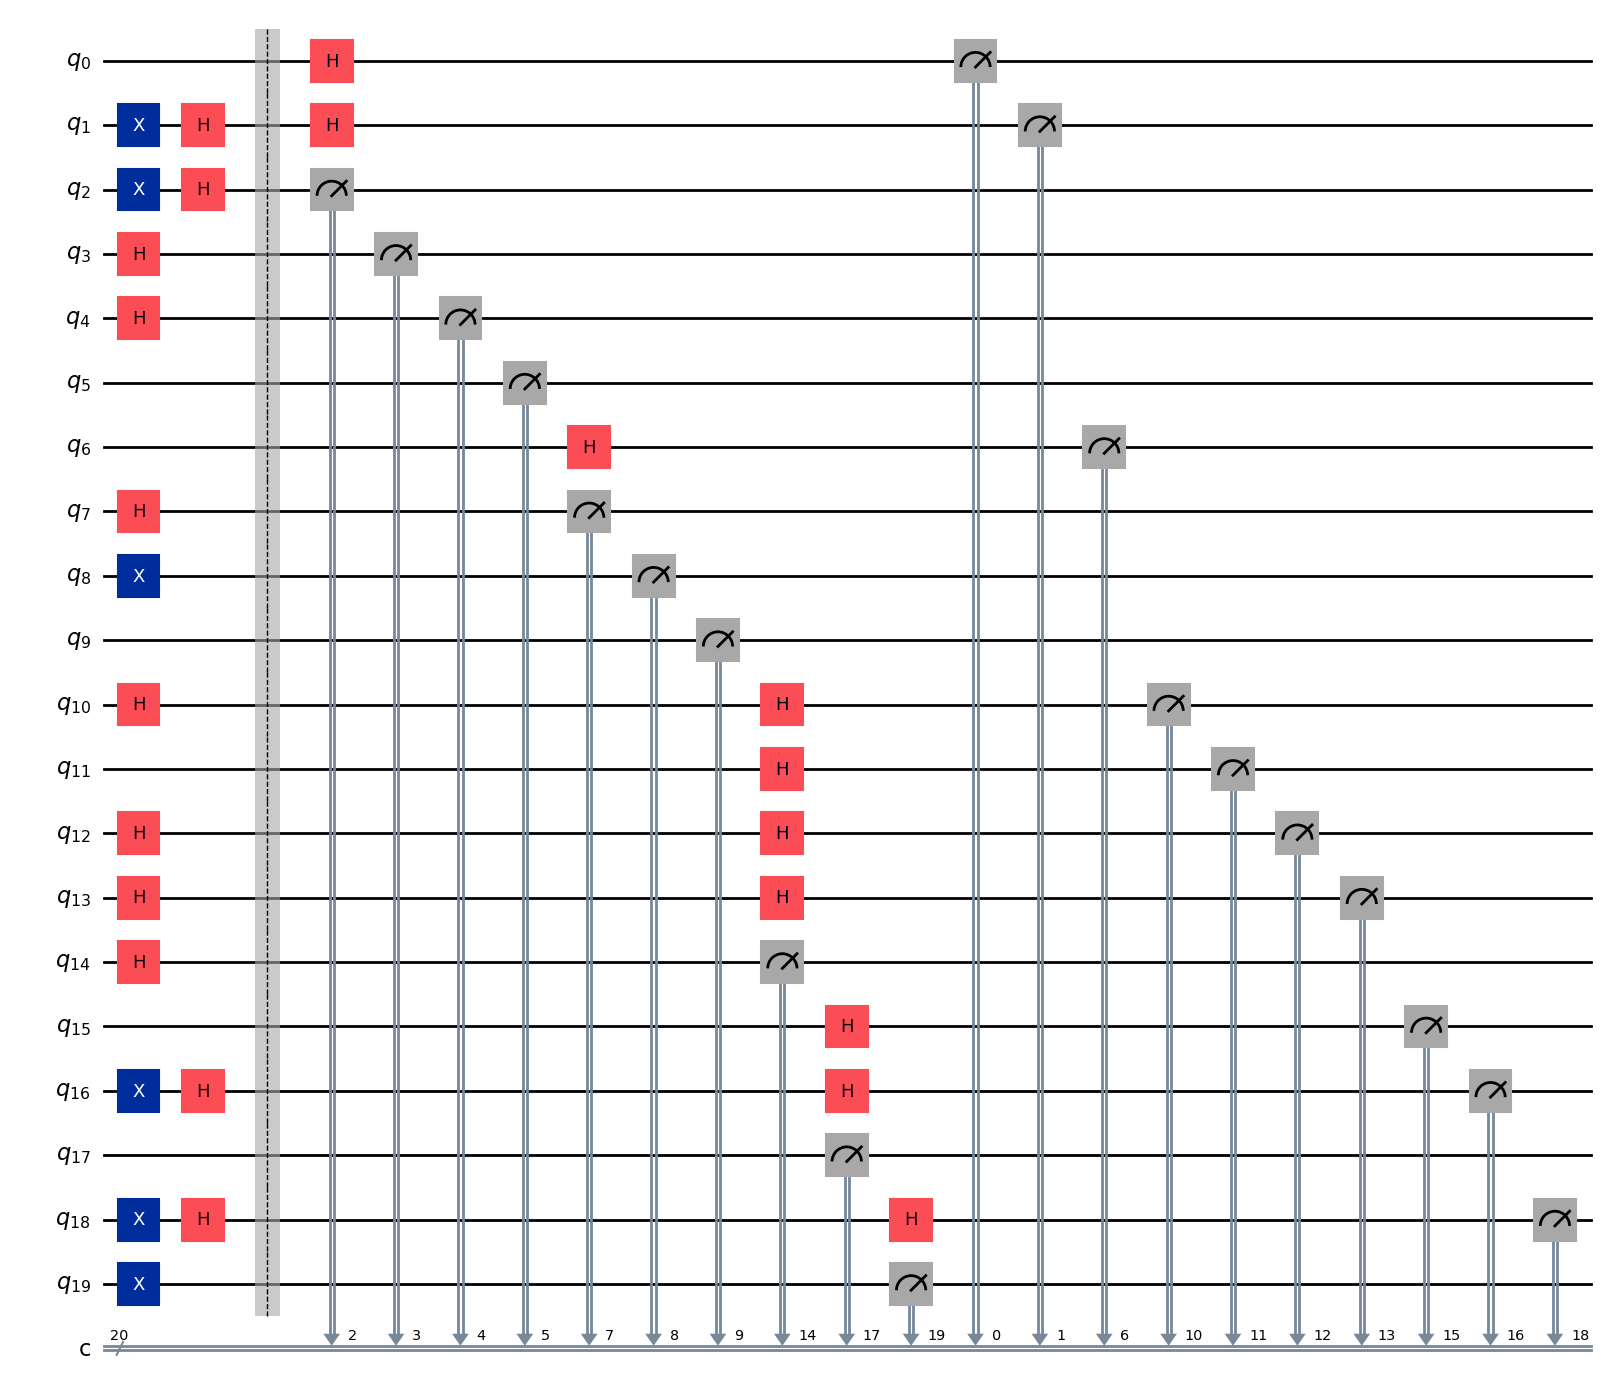

In [111]:
# second circuit - what Bob receives, then Bob measures
qc2 = QuantumCircuit(n_qubits, n_qubits)

for n in range(n_qubits):
    if eve_attacks[n]:
        prepare_state(qc2, n, eve_bits[n], eve_bases[n])       # Eve resends her result
    else:
        prepare_state(qc2, n, alice_bits[n], alice_bases[n])   # original state is passed

qc2.barrier()

for n in range(n_qubits):
    measure(qc2, n, bob_bases[n])

qc2.draw("mpl", style="iqp")

In [112]:
# run second circuit to get Bob's results
bob_bits = run_circuit(qc2, SEED + 1)
print("Bob bits:", bob_bits)

Bob bits: [0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1]


In [113]:
# key sifting - keep positions where Alice and Bob used the same basis
alice_sifted = []
bob_sifted = []

for n in range(n_qubits):
    if alice_bases[n] == bob_bases[n]:
        alice_sifted.append(alice_bits[n])
        bob_sifted.append(bob_bits[n])

print("Alice sifted:", alice_sifted)
print("Bob sifted  :", bob_sifted)

Alice sifted: [0, 1, 0, 0, 0, 0, 1, 0, 1, 1]
Bob sifted  : [0, 1, 0, 0, 0, 0, 1, 0, 1, 1]


In [114]:
# choose k random sifted positions, count the errors, calculate QBER
k_used = min(k, len(alice_sifted))
sample = random.sample(range(len(alice_sifted)), k_used)

errors = 0
for i in sample:
    if alice_sifted[i] != bob_sifted[i]:
        errors = errors + 1

qber = errors / k_used
print("Compared", k_used, "bits, errors:", errors, " QBER:", qber)

# decide whether to keep or abort the sifted key
if qber > threshold:
    print("QBER above threshold: abort the key")
else:
    print("QBER at or below threshold: accept the key")

print("Eve attacks:", eve_attacks)
print(f"Attacked {sum(eve_attacks)} / {n_qubits} qubits")

Compared 10 bits, errors: 0  QBER: 0.0
QBER at or below threshold: accept the key
Eve attacks: [False, True, False, True, False, False, False, False, False, False, False, True, True, False, False, True, False, False, False, False]
Attacked 5 / 20 qubits
